In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
production = pd.read_csv("/content/production_records.csv")

machines = pd.read_csv("/content/machines.csv")

ground_truth = pd.read_csv(
    "/content/ground_truth_anomalies.csv"
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
print("PRODUCTION DATA")
display(production.head())

print("MACHINE DATA")
display(machines)

print("GROUND TRUTH ANOMALIES")
display(ground_truth.head())

PRODUCTION DATA


,record_id,date,shift,machine_id,line_id,planned_output,actual_output,defect_count,downtime_minutes,operating_minutes,shift_duration_minutes,dataset_notice
0,20260101-A-M-01,2026-01-01,A,M-01,L-01,500,483,13,14,466,480,SYNTHETIC DATA - SIMULATED MANUFACTURING SCENA...
1,20260101-A-M-02,2026-01-01,A,M-02,L-01,450,442,21,15,465,480,SYNTHETIC DATA - SIMULATED MANUFACTURING SCENA...
2,20260101-A-M-03,2026-01-01,A,M-03,L-01,600,577,5,13,467,480,SYNTHETIC DATA - SIMULATED MANUFACTURING SCENA...
3,20260101-A-M-04,2026-01-01,A,M-04,L-02,400,375,14,34,446,480,SYNTHETIC DATA - SIMULATED MANUFACTURING SCENA...
4,20260101-A-M-05,2026-01-01,A,M-05,L-02,550,528,10,25,455,480,SYNTHETIC DATA - SIMULATED MANUFACTURING SCENA...


MACHINE DATA


,machine_id,line_id,baseline_output,baseline_downtime,defect_rate,dataset_notice
0,M-01,L-01,500,20,0.020,SYNTHETIC DATA - SIMULATED MANUFACTURING SCENA...
1,M-02,L-01,450,25,0.030,SYNTHETIC DATA - SIMULATED MANUFACTURING SCENA...
2,M-03,L-01,600,15,0.015,SYNTHETIC DATA - SIMULATED MANUFACTURING SCENA...
3,M-04,L-02,400,30,0.025,SYNTHETIC DATA - SIMULATED MANUFACTURING SCENA...
4,M-05,L-02,550,20,0.020,SYNTHETIC DATA - SIMULATED MANUFACTURING SCENA...
5,M-06,L-02,480,18,0.018,SYNTHETIC DATA - SIMULATED MANUFACTURING SCENA...


GROUND TRUTH ANOMALIES


,record_id,machine_id,date,shift,anomaly_type,severity,description,dataset_notice
0,20260121-B-M-01,M-01,2026-01-21,B,downtime_spike,high,Unusually high machine downtime,SYNTHETIC DATA - SIMULATED MANUFACTURING SCENA...
1,20260131-A-M-02,M-02,2026-01-31,A,defect_surge,high,Defect rate increased significantly,SYNTHETIC DATA - SIMULATED MANUFACTURING SCENA...
2,20260210-C-M-04,M-04,2026-02-10,C,production_drop,high,Sudden reduction in production output,SYNTHETIC DATA - SIMULATED MANUFACTURING SCENA...
3,20260222-A-M-06,M-06,2026-02-22,A,gradual_deterioration,medium,Gradual decline in production output,SYNTHETIC DATA - SIMULATED MANUFACTURING SCENA...
4,20260222-B-M-06,M-06,2026-02-22,B,gradual_deterioration,medium,Gradual decline in production output,SYNTHETIC DATA - SIMULATED MANUFACTURING SCENA...


In [4]:
print("Production shape:", production.shape)
print("Machines shape:", machines.shape)
print("Ground truth shape:", ground_truth.shape)

print("\nProduction columns:")
print(production.columns.tolist())

print("\nData types:")
print(production.dtypes)

Production shape: (1080, 12)
Machines shape: (6, 6)
Ground truth shape: (27, 8)

Production columns:
['record_id', 'date', 'shift', 'machine_id', 'line_id', 'planned_output', 'actual_output', 'defect_count', 'downtime_minutes', 'operating_minutes', 'shift_duration_minutes', 'dataset_notice']

Data types:
record_id                 object
date                      object
shift                     object
machine_id                object
line_id                   object
planned_output             int64
actual_output              int64
defect_count               int64
downtime_minutes           int64
operating_minutes          int64
shift_duration_minutes     int64
dataset_notice            object
dtype: object


In [5]:
production["date"] = pd.to_datetime(production["date"])

print(production["date"].dtype)

datetime64[ns]


In [6]:
production["achievement_pct"] = (
    production["actual_output"] /
    production["planned_output"]
) * 100

production["defect_rate_pct"] = (
    production["defect_count"] /
    production["actual_output"]
) * 100

production["downtime_pct"] = (
    production["downtime_minutes"] /
    production["shift_duration_minutes"]
) * 100

production["yield_pct"] = (
    (production["actual_output"] - production["defect_count"]) /
    production["actual_output"]
) * 100

In [7]:
kpi_columns = [
    "achievement_pct",
    "defect_rate_pct",
    "downtime_pct",
    "yield_pct"
]

display(production[kpi_columns].describe().round(2))

,achievement_pct,defect_rate_pct,downtime_pct,yield_pct
count,1080.00,1080.00,1080.00,1080.00
mean,95.18,2.13,4.36,97.87
std,5.16,0.91,1.69,0.91
min,41.00,0.23,0.62,88.08
25%,94.00,1.51,3.33,97.38
50%,95.65,2.00,4.17,98.00
75%,97.28,2.62,5.42,98.49
max,103.64,11.92,31.25,99.77


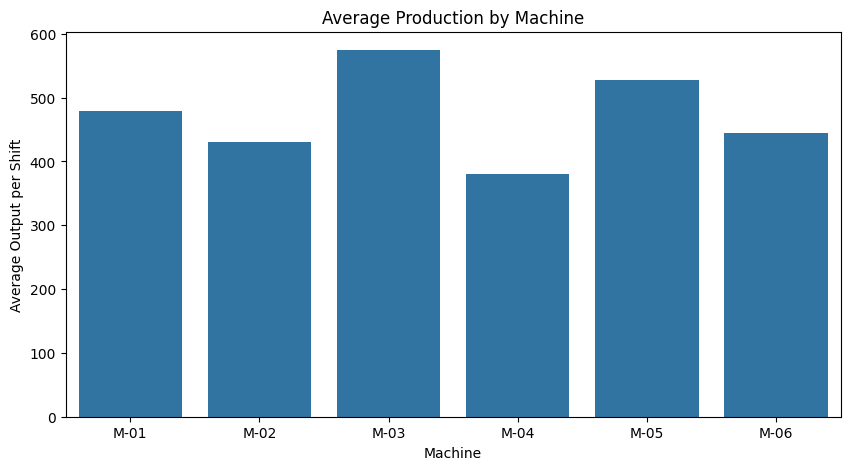

In [8]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=production,
    x="machine_id",
    y="actual_output",
    estimator="mean",
    errorbar=None
)

plt.title("Average Production by Machine")
plt.xlabel("Machine")
plt.ylabel("Average Output per Shift")
plt.show()

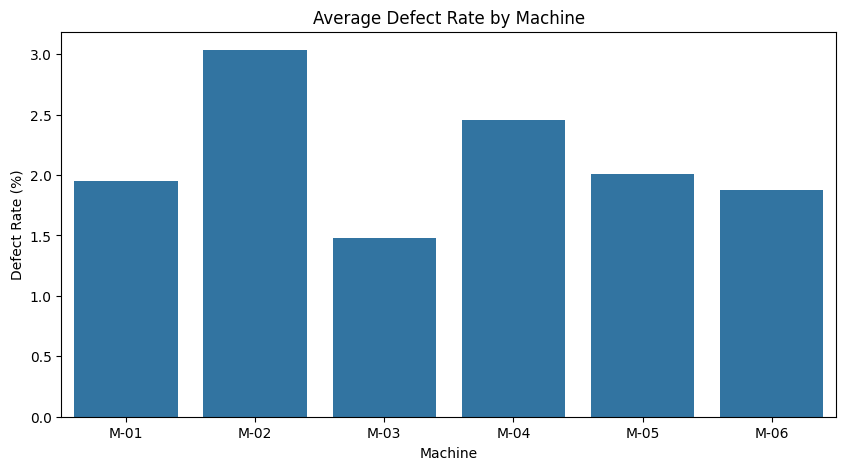

In [9]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=production,
    x="machine_id",
    y="defect_rate_pct",
    errorbar=None
)

plt.title("Average Defect Rate by Machine")
plt.xlabel("Machine")
plt.ylabel("Defect Rate (%)")
plt.show()

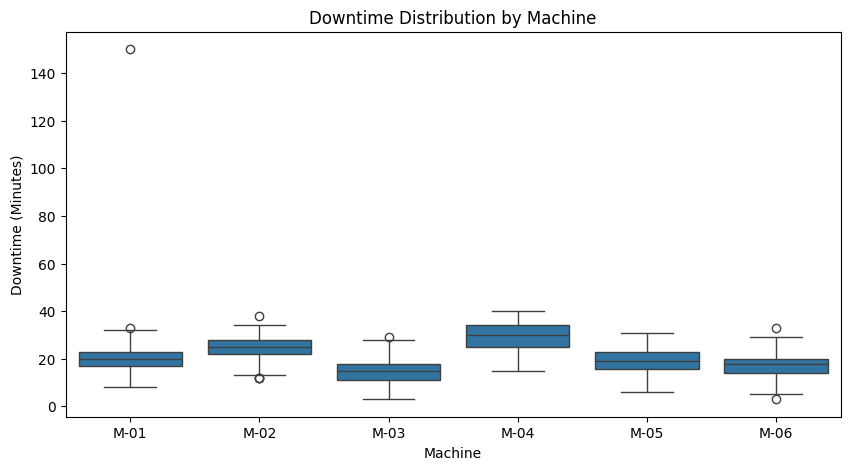

In [10]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=production,
    x="machine_id",
    y="downtime_minutes"
)

plt.title("Downtime Distribution by Machine")
plt.xlabel("Machine")
plt.ylabel("Downtime (Minutes)")
plt.show()

In [11]:
production.nlargest(
    10,
    "downtime_minutes"
)[
    ["date", "machine_id", "shift", "downtime_minutes"]
]

,date,machine_id,shift,downtime_minutes
366,2026-01-21,M-01,B,150
435,2026-01-25,M-04,A,40
999,2026-02-25,M-04,B,40
153,2026-01-09,M-04,B,39
201,2026-01-12,M-04,A,39
285,2026-01-16,M-04,C,39
471,2026-01-27,M-04,A,39
981,2026-02-24,M-04,B,39
1041,2026-02-27,M-04,C,39
381,2026-01-22,M-04,A,38


In [12]:
downtime_summary = production.groupby("machine_id")[
    "downtime_minutes"
].agg(
    ["mean", "median", "std", "max"]
).round(2)

display(downtime_summary)

,mean,median,std,max
machine_id,,,,
M-01,20.46,20.0,10.88,150
M-02,24.67,25.0,4.81,38
M-03,14.53,15.0,5.21,29
M-04,29.47,30.0,5.48,40
M-05,19.07,19.0,5.36,31
M-06,17.42,18.0,4.79,33


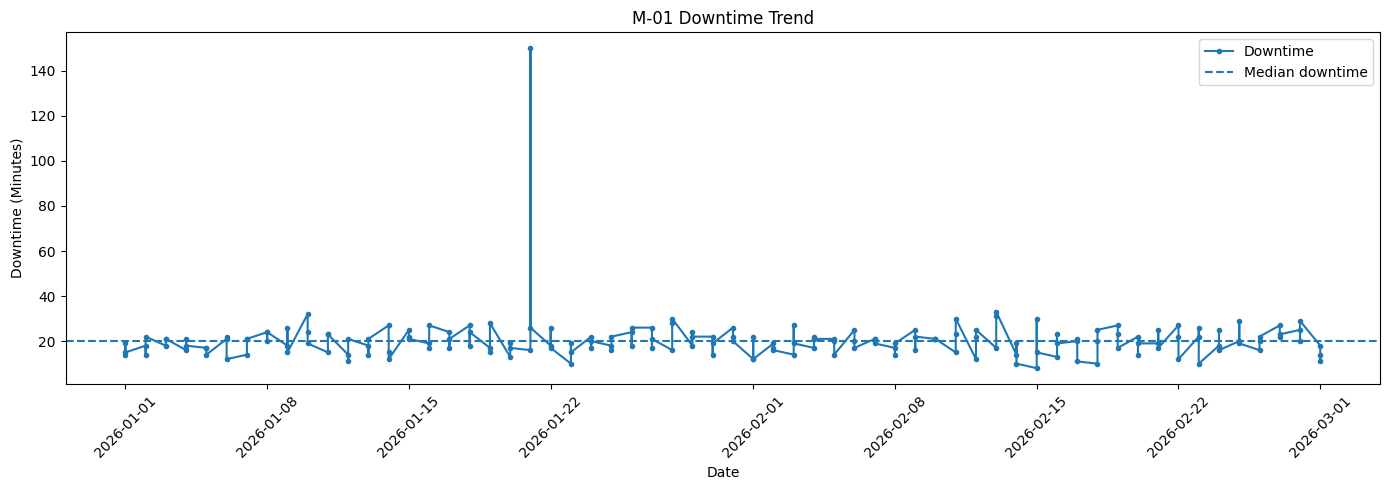

In [13]:
plt.figure(figsize=(14, 5))

m01 = production[
    production["machine_id"] == "M-01"
]

plt.plot(
    m01["date"],
    m01["downtime_minutes"],
    marker="o",
    markersize=3,
    label="Downtime"
)

plt.axhline(
    m01["downtime_minutes"].median(),
    linestyle="--",
    label="Median downtime"
)

plt.title("M-01 Downtime Trend")
plt.xlabel("Date")
plt.ylabel("Downtime (Minutes)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

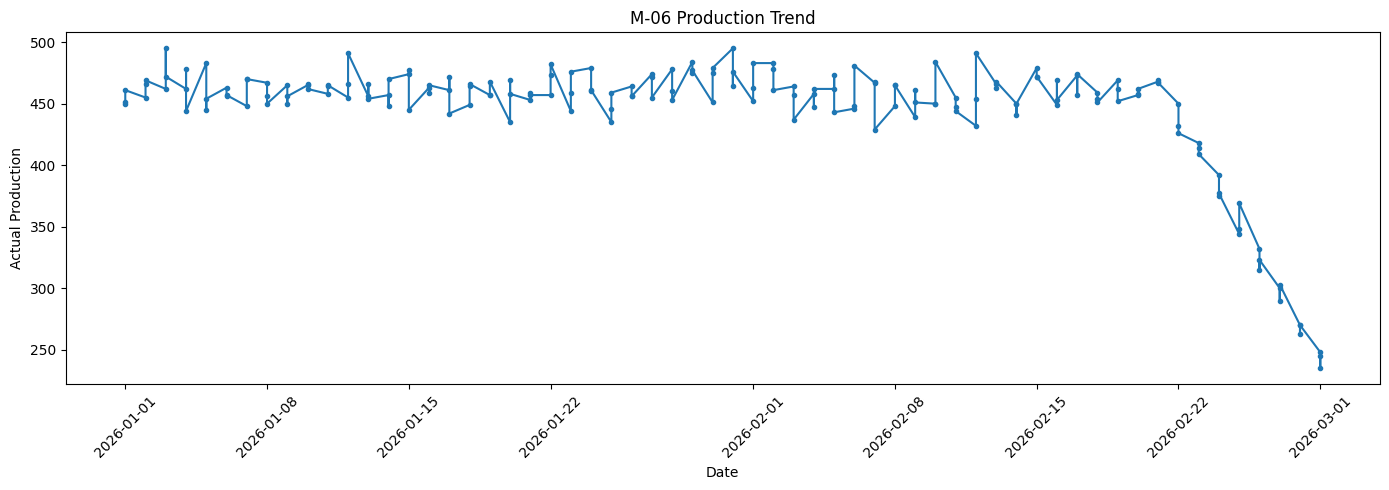

In [14]:
plt.figure(figsize=(14, 5))

m06 = production[
    production["machine_id"] == "M-06"
]

plt.plot(
    m06["date"],
    m06["actual_output"],
    marker="o",
    markersize=3
)

plt.title("M-06 Production Trend")
plt.xlabel("Date")
plt.ylabel("Actual Production")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
anomaly_data = production.merge(
    ground_truth[["record_id", "anomaly_type"]],
    on="record_id",
    how="left"
)

anomaly_data["anomaly_type"] = (
    anomaly_data["anomaly_type"].fillna("normal")
)

print(anomaly_data["anomaly_type"].value_counts())

anomaly_type
normal                   1053
gradual_deterioration      24
downtime_spike              1
defect_surge                1
production_drop             1
Name: count, dtype: int64


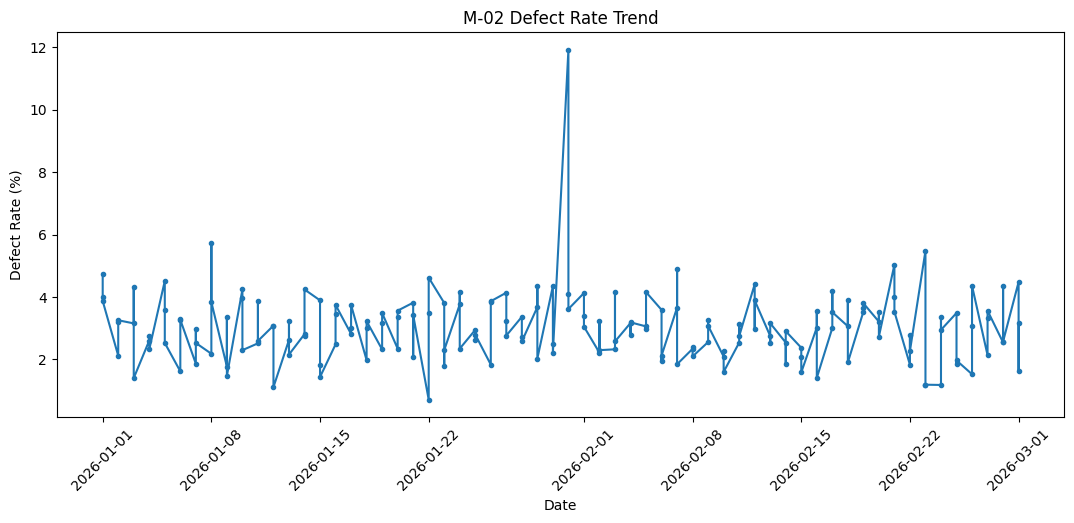

In [16]:
m02 = production[
    production["machine_id"] == "M-02"
].copy()

m02["defect_rate_pct"] = (
    m02["defect_count"] / m02["actual_output"]
) * 100

plt.figure(figsize=(13, 5))

plt.plot(
    m02["date"], m02["defect_rate_pct"],
    marker="o", markersize=3
)

plt.title("M-02 Defect Rate Trend")
plt.xlabel("Date")
plt.ylabel("Defect Rate (%)")
plt.xticks(rotation=45)
plt.show()

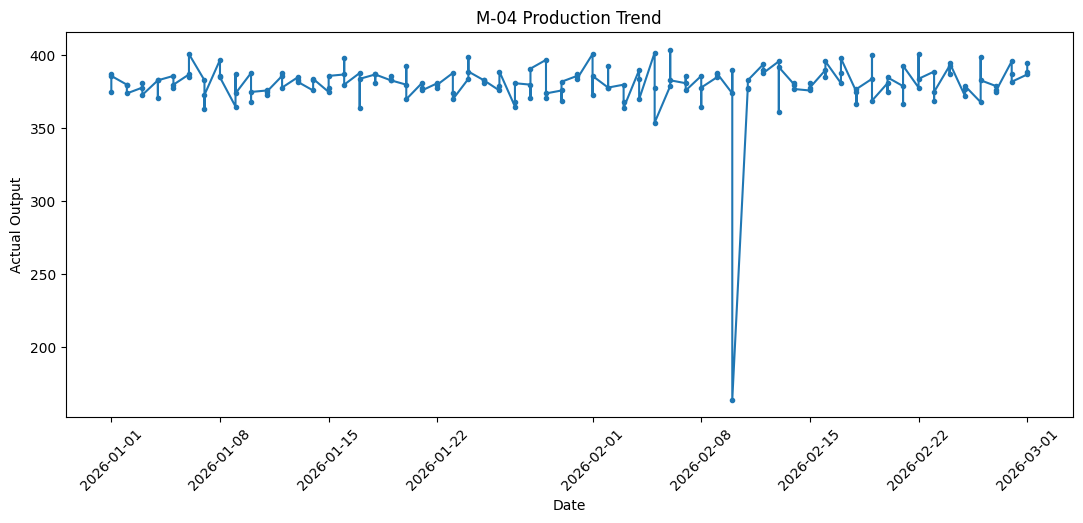

In [17]:
m04 = production[
    production["machine_id"] == "M-04"
]

plt.figure(figsize=(13, 5))

plt.plot(
    m04["date"], m04["actual_output"],
    marker="o", markersize=3
)

plt.title("M-04 Production Trend")
plt.xlabel("Date")
plt.ylabel("Actual Output")
plt.xticks(rotation=45)
plt.show()

In [18]:
display(
    anomaly_data[
        anomaly_data["anomaly_type"] != "normal"
    ][
        [
            "date",
            "shift",
            "machine_id",
            "actual_output",
            "defect_count",
            "downtime_minutes",
            "anomaly_type"
        ]
    ].head(30)
)

,date,shift,machine_id,actual_output,defect_count,downtime_minutes,anomaly_type
366,2026-01-21,B,M-01,478,8,150,downtime_spike
541,2026-01-31,A,M-02,428,51,31,defect_surge
735,2026-02-10,C,M-04,164,11,24,production_drop
941,2026-02-22,A,M-06,450,8,21,gradual_deterioration
947,2026-02-22,B,M-06,432,1,15,gradual_deterioration
953,2026-02-22,C,M-06,426,6,22,gradual_deterioration
959,2026-02-23,A,M-06,418,6,22,gradual_deterioration
965,2026-02-23,B,M-06,414,12,25,gradual_deterioration
971,2026-02-23,C,M-06,409,10,19,gradual_deterioration
977,2026-02-24,A,M-06,392,9,15,gradual_deterioration
